# Import Decision Tree Libraries

In [1]:
# Decision Tree Libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    roc_curve
)

print("Decision Tree libraries imported successfully!")

Decision Tree libraries imported successfully!


In [4]:
required_variables = [
    "X_train_balanced",
    "y_train_balanced",
    "X_val",
    "y_val",
    "X_test_sample",
    "y_test_sample",
    "extract_hog_features"
]

for var in required_variables:
    print(var, ":", "Available" if var in globals() else "Missing")

X_train_balanced : Missing
y_train_balanced : Missing
X_val : Missing
y_val : Missing
X_test_sample : Missing
y_test_sample : Missing
extract_hog_features : Missing


In [5]:

# ==========================================
# DECISION TREE - COMPLETE DATA PREPARATION
# ==========================================

import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from skimage.feature import hog
from sklearn.model_selection import GroupShuffleSplit
from sklearn.tree import DecisionTreeClassifier, plot_tree

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report,
    roc_auc_score, roc_curve
)

# 1. Dataset path
DATASET_PATH = r"C:\Users\utkri\Downloads\archive (2)\IDC_regular_ps50_idx5"

if not os.path.exists(DATASET_PATH):
    raise FileNotFoundError("Dataset path not found!")

# 2. Load images, labels and patient IDs
image_paths, labels, patient_ids = [], [], []

for patient in os.listdir(DATASET_PATH):
    patient_path = os.path.join(DATASET_PATH, patient)

    if not os.path.isdir(patient_path):
        continue

    for label in ["0", "1"]:
        class_path = os.path.join(patient_path, label)

        if not os.path.isdir(class_path):
            continue

        for filename in os.listdir(class_path):
            if filename.lower().endswith(".png"):
                image_paths.append(os.path.join(class_path, filename))
                labels.append(int(label))
                patient_ids.append(patient)

image_paths = np.array(image_paths)
labels = np.array(labels)
patient_ids = np.array(patient_ids)

print("Total Images:", len(image_paths))

# 3. Patient-wise train/test split
splitter = GroupShuffleSplit(
    n_splits=1, test_size=0.20, random_state=42
)

train_idx, test_idx = next(
    splitter.split(image_paths, labels, patient_ids)
)

X_train_paths = image_paths[train_idx]
y_train = labels[train_idx]
train_groups = patient_ids[train_idx]

X_test_paths = image_paths[test_idx]
y_test = labels[test_idx]

# 4. Patient-wise validation split
splitter_val = GroupShuffleSplit(
    n_splits=1, test_size=0.15, random_state=42
)

new_train_idx, val_idx = next(
    splitter_val.split(X_train_paths, y_train, train_groups)
)

X_train_final = X_train_paths[new_train_idx]
y_train_final = y_train[new_train_idx]

X_val_paths = X_train_paths[val_idx]
y_val_all = y_train[val_idx]

# 5. Balanced training sample
rng = np.random.default_rng(42)

class_0 = np.where(y_train_final == 0)[0]
class_1 = np.where(y_train_final == 1)[0]

n = min(2000, len(class_0), len(class_1))

selected = np.concatenate([
    rng.choice(class_0, n, replace=False),
    rng.choice(class_1, n, replace=False)
])

rng.shuffle(selected)

X_train_balanced = X_train_final[selected]
y_train_balanced = y_train_final[selected]

# 6. Balanced validation and test samples
def balanced_sample(paths, targets, samples=1000):
    rng_local = np.random.default_rng(42)

    idx0 = np.where(targets == 0)[0]
    idx1 = np.where(targets == 1)[0]

    count = min(samples, len(idx0), len(idx1))

    chosen = np.concatenate([
        rng_local.choice(idx0, count, replace=False),
        rng_local.choice(idx1, count, replace=False)
    ])

    rng_local.shuffle(chosen)

    return paths[chosen], targets[chosen]

X_val, y_val = balanced_sample(X_val_paths, y_val_all)
X_test_sample, y_test_sample = balanced_sample(X_test_paths, y_test)

# 7. HOG feature extraction
def extract_hog_features(image_path):
    image = cv2.imread(image_path)

    if image is None:
        raise ValueError(f"Cannot read image: {image_path}")

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
    gray = cv2.resize(gray, (64, 64))

    return hog(
        gray.astype(np.float32),
        orientations=9,
        pixels_per_cell=(8, 8),
        cells_per_block=(2, 2),
        block_norm="L2-Hys"
    )

# 8. Extract features
print("\nExtracting Training HOG Features...")

X_train_features = np.array([
    extract_hog_features(p) for p in X_train_balanced
])

print("Extracting Validation HOG Features...")

X_val_features = np.array([
    extract_hog_features(p) for p in X_val
])

print("Extracting Test HOG Features...")

X_test_features = np.array([
    extract_hog_features(p) for p in X_test_sample
])

# 9. Final verification
print("\n========== PREPARATION COMPLETE ==========")
print("Training:", X_train_features.shape)
print("Validation:", X_val_features.shape)
print("Testing:", X_test_features.shape)

print("\nTraining Labels:", np.unique(y_train_balanced, return_counts=True))
print("Validation Labels:", np.unique(y_val, return_counts=True))
print("Testing Labels:", np.unique(y_test_sample, return_counts=True))


Total Images: 277524

Extracting Training HOG Features...
Extracting Validation HOG Features...
Extracting Test HOG Features...

========== PREPARATION COMPLETE ==========
Training: (4000, 1764)
Validation: (2000, 1764)
Testing: (2000, 1764)

Training Labels: (array([0, 1]), array([2000, 2000]))
Validation Labels: (array([0, 1]), array([1000, 1000]))
Testing Labels: (array([0, 1]), array([1000, 1000]))


# Train Decision Tree with Different Max Depth Values

In [6]:

# Step 3: Decision Tree Model Training

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

depth_values = [5, 10, 15, 20, None]

dt_results = []

for depth in depth_values:

    print(f"\nTraining Decision Tree - Max Depth: {depth}")

    dt_model = DecisionTreeClassifier(
        criterion="gini",
        max_depth=depth,
        min_samples_split=10,
        min_samples_leaf=5,
        random_state=42
    )

    # Train model
    dt_model.fit(X_train_features, y_train_balanced)

    # Validation prediction
    y_val_pred = dt_model.predict(X_val_features)

    # Calculate performance metrics
    accuracy = accuracy_score(y_val, y_val_pred)
    precision = precision_score(y_val, y_val_pred, zero_division=0)
    recall = recall_score(y_val, y_val_pred, zero_division=0)
    f1 = f1_score(y_val, y_val_pred, zero_division=0)

    dt_results.append({
        "Max Depth": str(depth),
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

    print("Accuracy:", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))

# Results comparison
dt_results_df = pd.DataFrame(dt_results)

print("\nDECISION TREE MODEL COMPARISON")
display(dt_results_df)



Training Decision Tree - Max Depth: 5
Accuracy: 0.5675
Precision: 0.5468
Recall: 0.789
F1-Score: 0.6459

Training Decision Tree - Max Depth: 10
Accuracy: 0.5685
Precision: 0.5538
Recall: 0.705
F1-Score: 0.6203

Training Decision Tree - Max Depth: 15
Accuracy: 0.555
Precision: 0.5494
Recall: 0.612
F1-Score: 0.579

Training Decision Tree - Max Depth: 20
Accuracy: 0.551
Precision: 0.5482
Recall: 0.58
F1-Score: 0.5637

Training Decision Tree - Max Depth: None
Accuracy: 0.5455
Precision: 0.5463
Recall: 0.537
F1-Score: 0.5416

DECISION TREE MODEL COMPARISON


,Max Depth,Accuracy,Precision,Recall,F1-Score
0,5,0.5675,0.546778,0.789,0.645927
1,10,0.5685,0.553810,0.705,0.620326
2,15,0.5550,0.549372,0.612,0.578997
3,20,0.5510,0.548204,0.580,0.563654
4,None,0.5455,0.546287,0.537,0.541604


# Visualize Model Performance

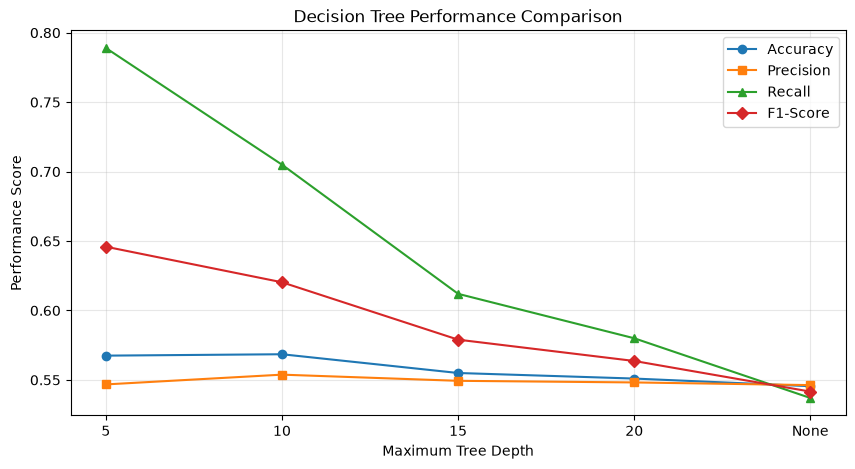

In [7]:
plt.figure(figsize=(10, 5))

plt.plot(dt_results_df["Max Depth"],
         dt_results_df["Accuracy"],
         marker="o", label="Accuracy")

plt.plot(dt_results_df["Max Depth"],
         dt_results_df["Precision"],
         marker="s", label="Precision")

plt.plot(dt_results_df["Max Depth"],
         dt_results_df["Recall"],
         marker="^", label="Recall")

plt.plot(dt_results_df["Max Depth"],
         dt_results_df["F1-Score"],
         marker="D", label="F1-Score")

plt.xlabel("Maximum Tree Depth")
plt.ylabel("Performance Score")
plt.title("Decision Tree Performance Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Train the Final Decision Tree Model

In [8]:

# Final Decision Tree Model

best_depth = 5

best_dt_model = DecisionTreeClassifier(
    criterion="gini",
    max_depth=best_depth,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# Train final model
best_dt_model.fit(X_train_features, y_train_balanced)

print("Final Decision Tree Model Trained!")
print("Selected Maximum Depth:", best_depth)


Final Decision Tree Model Trained!
Selected Maximum Depth: 5


# Evaluate on Test Dataset

In [9]:

# Test Dataset Prediction

y_test_pred_dt = best_dt_model.predict(X_test_features)

y_test_prob_dt = best_dt_model.predict_proba(
    X_test_features
)[:, 1]

print("DECISION TREE - TEST RESULTS")
print("--------------------------------")

print("Accuracy:",
      accuracy_score(y_test_sample, y_test_pred_dt))

print("Precision:",
      precision_score(y_test_sample, y_test_pred_dt))

print("Recall:",
      recall_score(y_test_sample, y_test_pred_dt))

print("F1-Score:",
      f1_score(y_test_sample, y_test_pred_dt))

print("ROC-AUC:",
      roc_auc_score(y_test_sample, y_test_prob_dt))

print("\nClassification Report:")

print(classification_report(
    y_test_sample,
    y_test_pred_dt,
    target_names=["Non-Cancerous", "Cancerous"]
))


DECISION TREE - TEST RESULTS
--------------------------------
Accuracy: 0.5885
Precision: 0.5581854043392505
Recall: 0.849
F1-Score: 0.6735422451408172
ROC-AUC: 0.6173900000000001

Classification Report:
               precision    recall  f1-score   support

Non-Cancerous       0.68      0.33      0.44      1000
    Cancerous       0.56      0.85      0.67      1000

     accuracy                           0.59      2000
    macro avg       0.62      0.59      0.56      2000
 weighted avg       0.62      0.59      0.56      2000



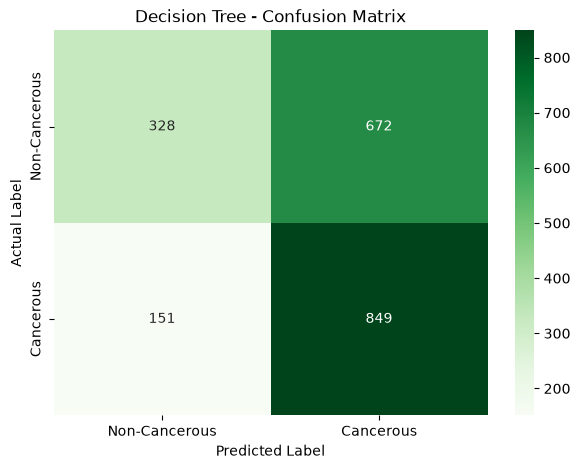

In [10]:
cm_dt = confusion_matrix(y_test_sample, y_test_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["Non-Cancerous", "Cancerous"],
    yticklabels=["Non-Cancerous", "Cancerous"]
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Decision Tree - Confusion Matrix")

plt.savefig("Decision_Tree_Confusion_Matrix.png", dpi=300)
plt.show()

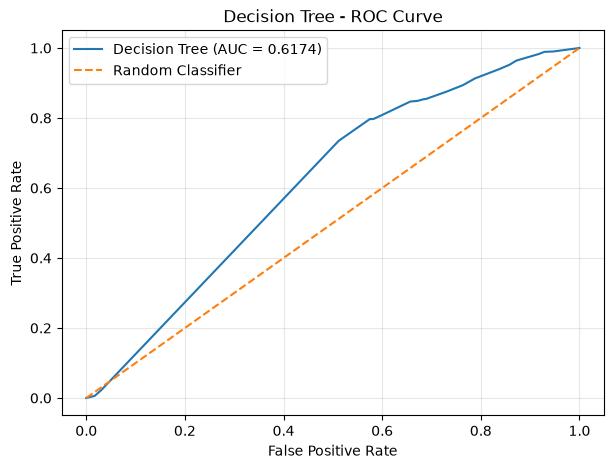

In [11]:
fpr_dt, tpr_dt, thresholds_dt = roc_curve(
    y_test_sample,
    y_test_prob_dt
)

auc_dt = roc_auc_score(y_test_sample, y_test_prob_dt)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr_dt,
    tpr_dt,
    label=f"Decision Tree (AUC = {auc_dt:.4f})"
)

plt.plot([0, 1], [0, 1], "--", label="Random Classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Decision Tree - ROC Curve")
plt.legend()
plt.grid(alpha=0.3)

plt.savefig("Decision_Tree_ROC_Curve.png", dpi=300)
plt.show()

# Decision Tree Model and Results

In [12]:

# Step 10: Save Decision Tree Model

import joblib

# Save trained model
joblib.dump(best_dt_model, "best_decision_tree_model.pkl")

print("Decision Tree Model Saved Successfully!")

# Save model comparison results
dt_results_df.to_csv(
    "Decision_Tree_Comparison.csv",
    index=False
)

# Save final test performance
dt_final_results = pd.DataFrame([{
    "Algorithm": "Decision Tree",
    "Best Max Depth": best_depth,
    "Accuracy": accuracy_score(y_test_sample, y_test_pred_dt),
    "Precision": precision_score(y_test_sample, y_test_pred_dt),
    "Recall": recall_score(y_test_sample, y_test_pred_dt),
    "F1-Score": f1_score(y_test_sample, y_test_pred_dt),
    "ROC-AUC": roc_auc_score(y_test_sample, y_test_prob_dt)
}])

dt_final_results.to_csv(
    "Decision_Tree_Final_Results.csv",
    index=False
)

print("\nExperimental Results Saved Successfully!")
display(dt_final_results)


Decision Tree Model Saved Successfully!

Experimental Results Saved Successfully!


,Algorithm,Best Max Depth,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Decision Tree,5,0.5885,0.558185,0.849,0.673542,0.61739


# Visualize the Decision Tree

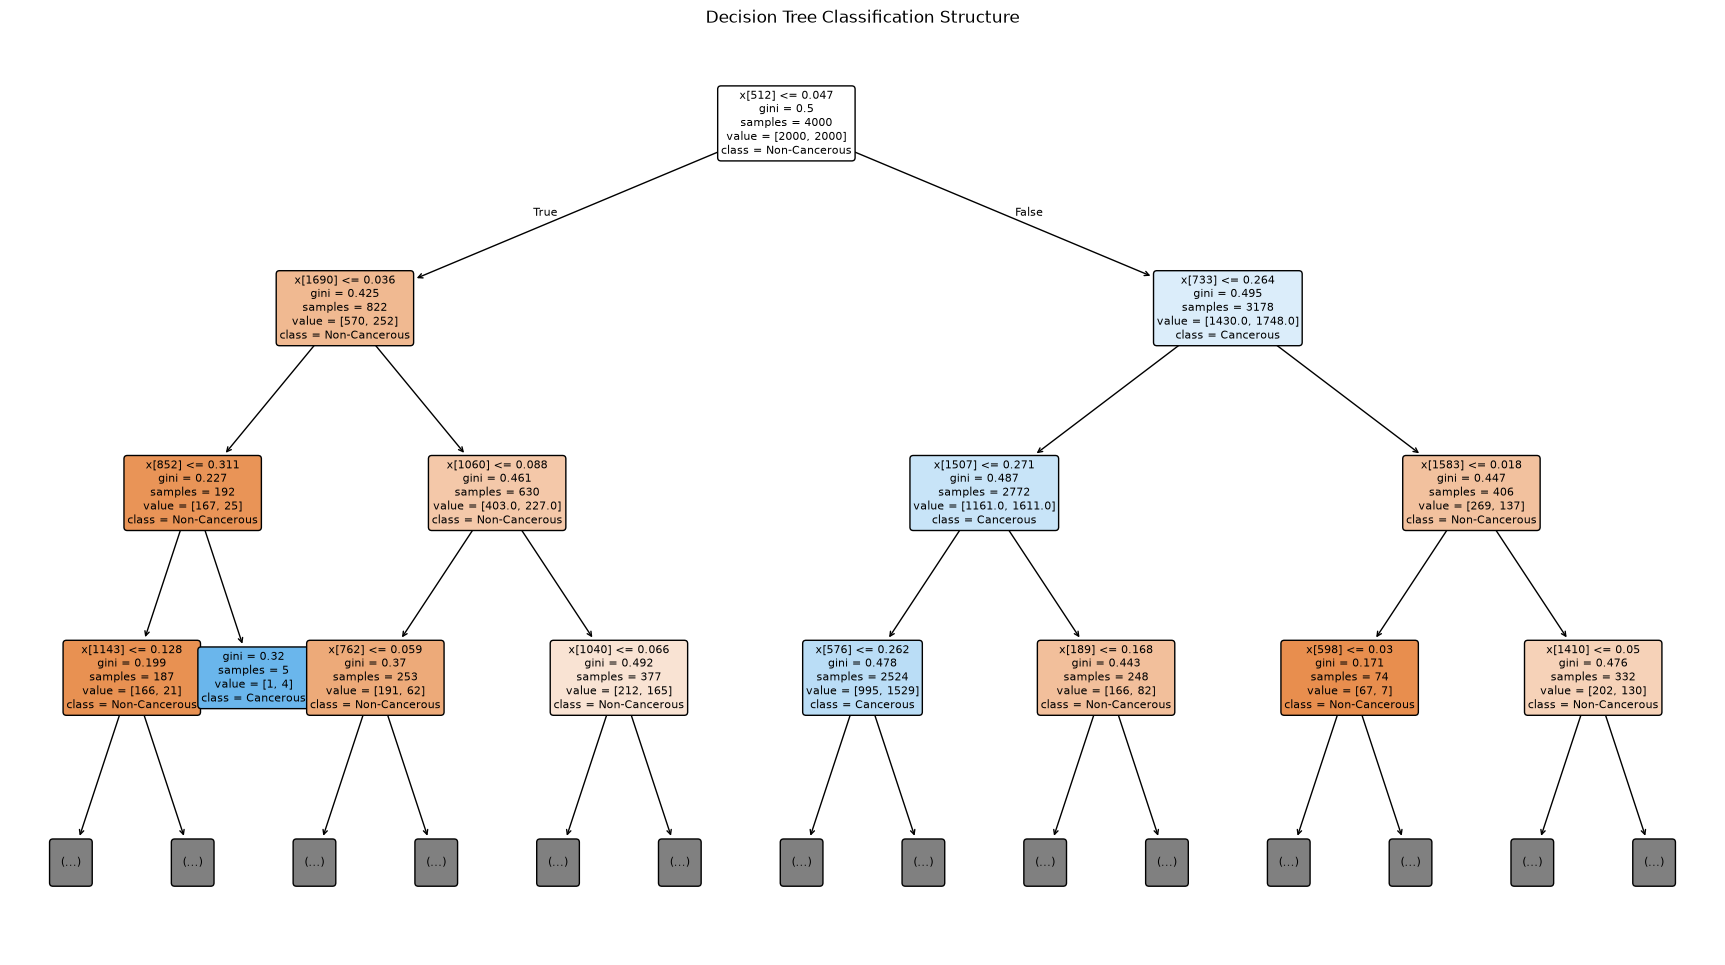

In [13]:
plt.figure(figsize=(22, 12))

plot_tree(
    best_dt_model,
    feature_names=None,
    class_names=["Non-Cancerous", "Cancerous"],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title("Decision Tree Classification Structure")
plt.savefig("Decision_Tree_Architecture.png", dpi=300, bbox_inches="tight")
plt.show()

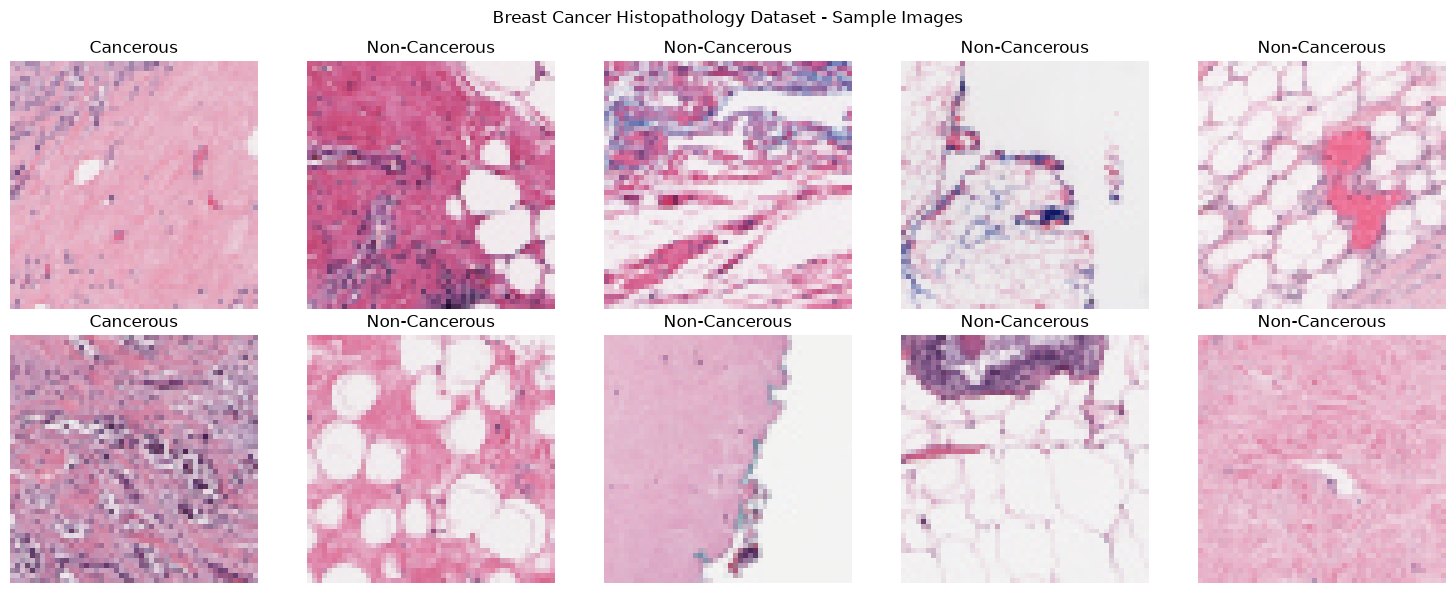

In [14]:
plt.figure(figsize=(15, 6))

indices = np.random.choice(len(image_paths), 10, replace=False)

for i, idx in enumerate(indices):
    img = plt.imread(image_paths[idx])

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title("Cancerous" if labels[idx] == 1 else "Non-Cancerous")
    plt.axis("off")

plt.suptitle("Breast Cancer Histopathology Dataset - Sample Images")
plt.tight_layout()
plt.show()

# Conclusion – Breast Cancer Histopathology Image Classification Using Decision Tree

This experiment successfully demonstrates the application of the Decision Tree Machine Learning algorithm for breast cancer histopathology image classification using the IDC dataset.

The workflow involved image preprocessing, Histogram of Oriented Gradients (HOG) feature extraction, and classification using Decision Tree. Different maximum tree depths (5, 10, 15, 20, and None) were evaluated to identify the best-performing configuration.

Based on validation performance, Max Depth = 5 achieved the highest F1-score of 64.59%, with an accuracy of 56.75% and recall of 78.90%.

The experiment highlights that increasing tree depth does not necessarily improve classification performance and may lead to reduced generalization.

Overall, this implementation provided practical experience in feature engineering, hyperparameter tuning, patient-wise data splitting, and model evaluation using accuracy, precision, recall, F1-score, confusion matrix, and ROC-AUC.

Future Scope: Further improvements can be explored using Random Forest, Gradient Boosting, feature selection, and advanced deep learning architectures such as CNN.